# 02 · Whole recording: whole-FOV trace and tile heatmaps under each baseline

These are the old notebooks' full-recording figures (the tile ΔF/F heatmaps in grid order, the whole-image ROI trace, and the zoomed window), redrawn under every baseline definition in `SPEC`. With `regress_running = True`, every figure uses running-regressed ΔF/F. The "What running removes" section shows original and regressed side by side either way. For multi-plane recordings, the whole-FOV trace is the mean of the per-plane ΔF/F, and the heatmaps are drawn per plane.

The heatmaps use viridis from 0 and are binned to `BIN_S` for display only. Gray marks missing or bad frames. Each method gets its own colour limit (99th percentile), because a fixed F₀ shifts the whole trace upward.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from nlight import analyses, analysis_plots as ap, plotting, recording_comparison, regression, session, state

plotting.use_lab_style()
RECORDINGS = session.load_recordings(Path('../../configs/nlight_recordings.json'))
print('Available:', list(RECORDINGS))

Available: ['corridor2 passive viewing', 'corridor2 baseline', 'passive (4 planes)', 'no puff (2x, 4 planes)', 'puff (2x, 4 planes)']


In [2]:
RECORDING = 'corridor2 passive viewing'   # any name from configs/nlight_recordings.json
# Baseline definitions applied to every analysis below. The first is the "current" method.
SPEC = recording_comparison.BaselineSpec(current_window_s=60, current_percentile=50,
                                         fixed_percentiles=(10,), long_windows_s=(180, 300, 600))
# True: every analysis below uses running-regressed ΔF/F (fitted per baseline method and per tile).
# The originals stay available as s['wf_original'] and each tile's 'dff_original'.
regress_running = False
# Running definition and regression model, shared by notebooks 02-04. threshold is in the
# behaviour table's speed units; check it against the speed histogram in notebook 04.
RUNNING_MODEL = regression.RunningModel(threshold=2.0, min_bout_s=1.0, min_lag_s=-1.0,
                                        max_lag_s=5.0, step_s=0.25, cv_folds=5, cv_gap_s=30.0)
BIN_S = 1.0
ZOOM_MIN = (1.0, 2.0)   # minutes; None to skip

In [3]:
s = session.open_session(RECORDINGS[RECORDING], SPEC, regress_running=regress_running,
                         running_model=RUNNING_MODEL)
print(s['n_planes'], 'plane(s),', f"{s['fs']:.3g} Hz,", f"{s['n_frames']/s['fs']/60:.1f} min",
      '· running-regressed ΔF/F' if s['regress_running'] else '· original ΔF/F')

1 plane(s), 30 Hz, 9.4 min · original ΔF/F


/Users/megyoung/mini2p-preprocessing/src/nlight/baseline_comparison.py:44: UserWarning: skipping 600 s window: recording is 563 s
  warnings.warn(f"skipping {seconds:g} s window: recording is {duration_s:.0f} s")


## Whole-FOV raw F and ΔF/F per baseline

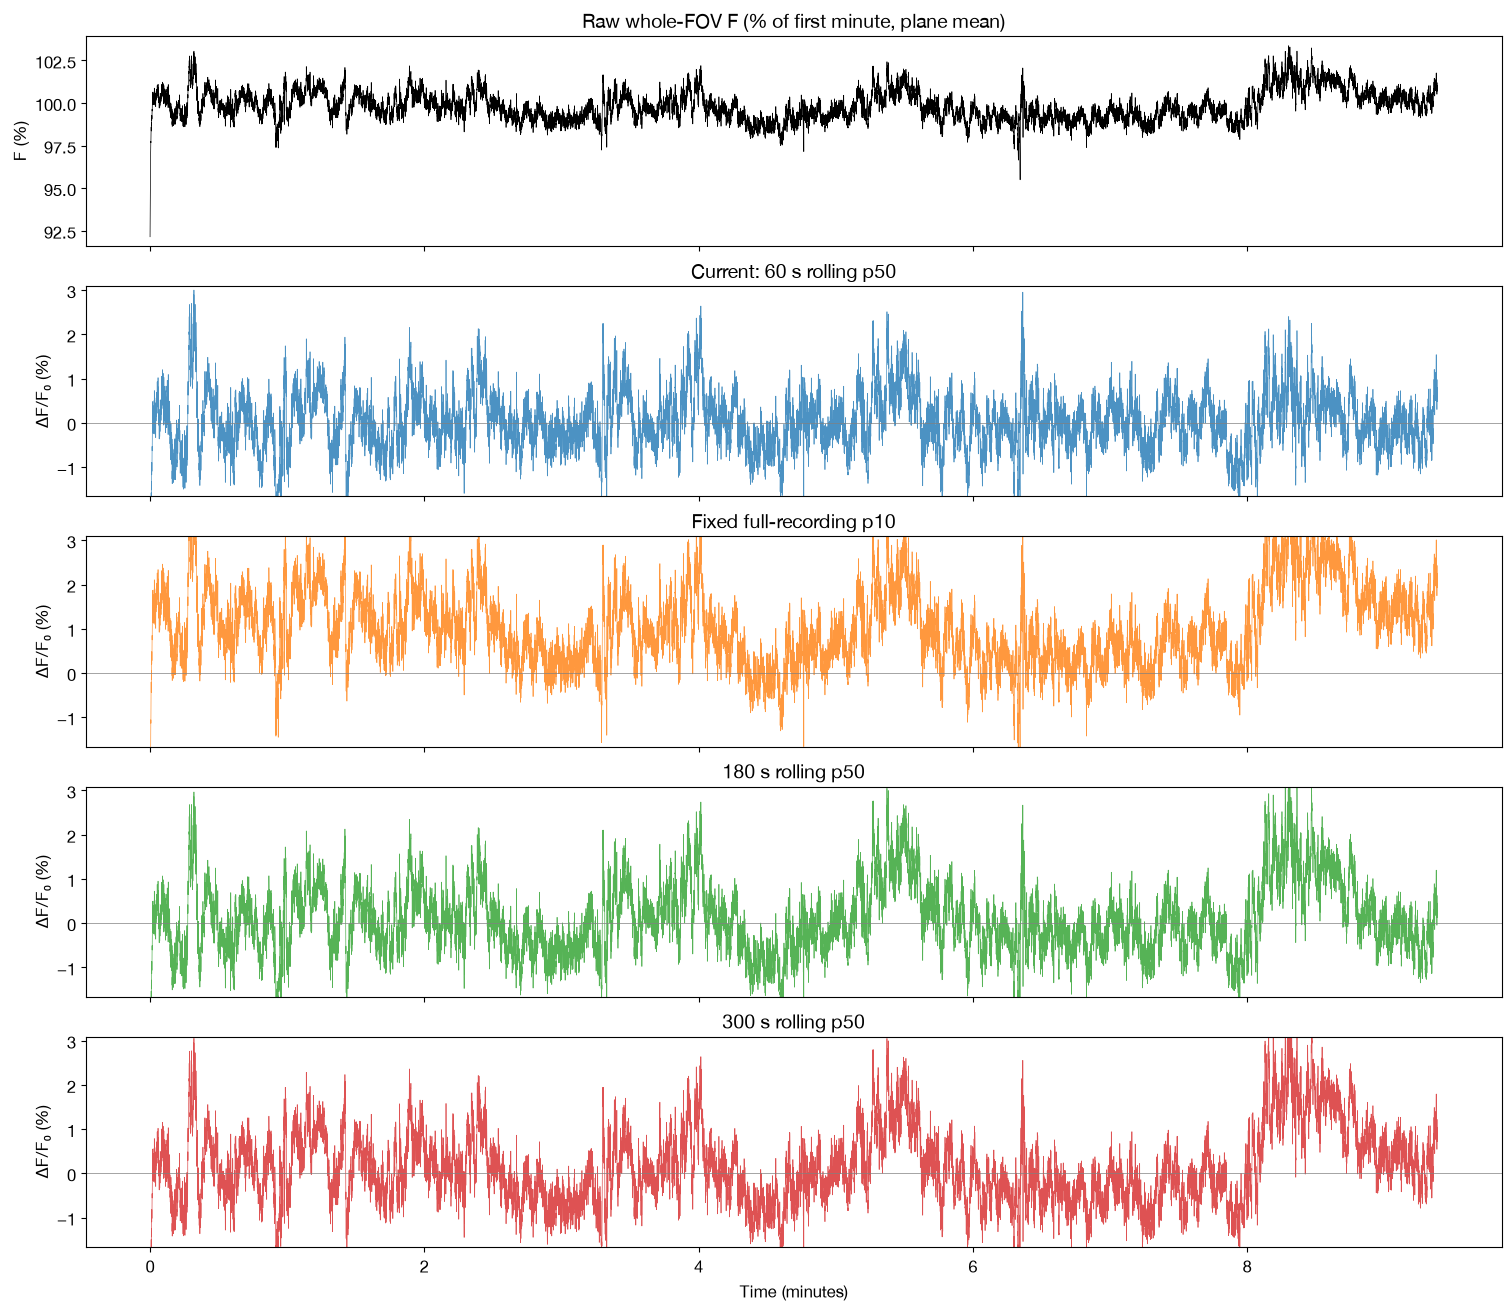

In [4]:
methods = list(s['wf'])
fig, axes = plt.subplots(len(methods) + 1, 1, figsize=(15, 2.6 * (len(methods) + 1)),
                         sharex=True, constrained_layout=True)
raw = recording_comparison.relative_raw_F(s['planes'])
axes[0].plot(s['time_s'] / 60, raw, color='black', lw=0.5)
axes[0].set(title='Raw whole-FOV F (% of first minute, plane mean)', ylabel='F (%)')
lo, hi = np.nanpercentile(np.concatenate([v * 100 for v in s['wf'].values()]), [0.5, 99.5])
for ax, color, m in zip(axes[1:], plotting._colors(len(methods)), methods):
    plotting.plot_dff(s['time_s'], s['wf'][m], ax, label=m, color=color)
    ax.set_ylim(lo, hi)
axes[-1].set_xlabel('Time (minutes)');

## Tile heatmaps per baseline

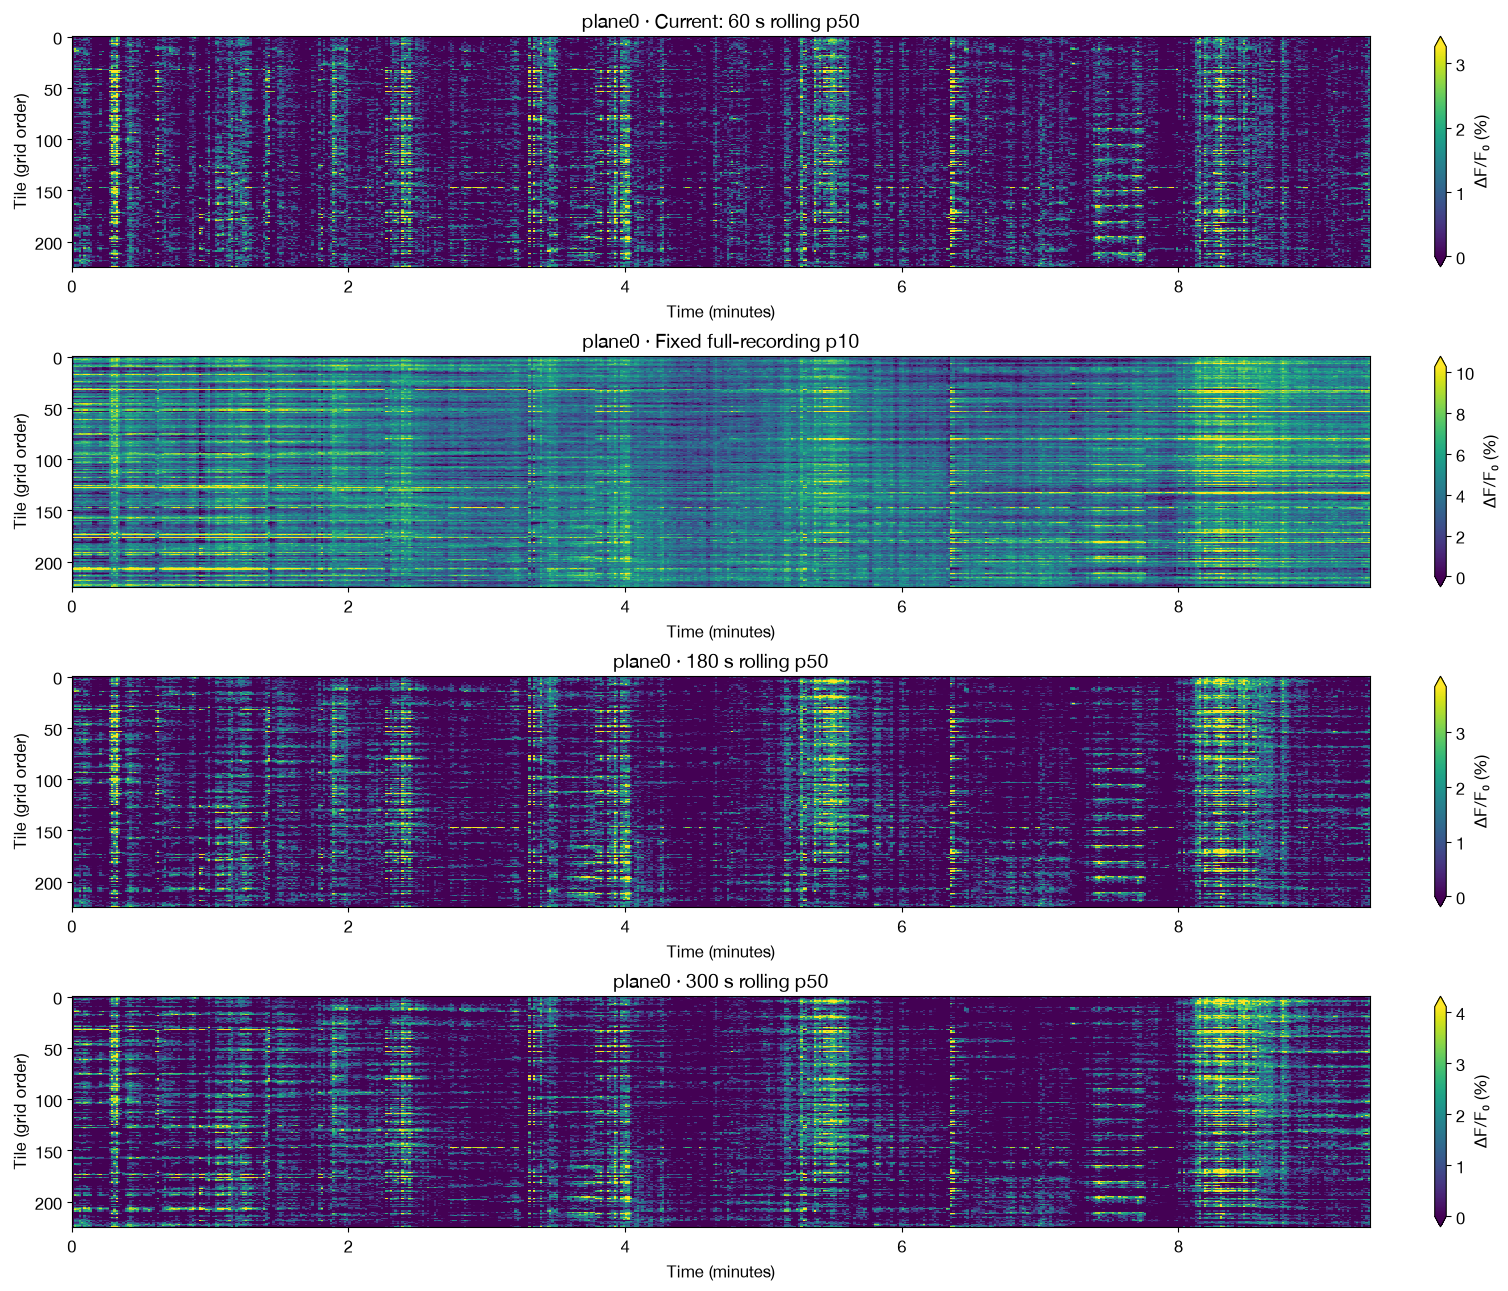

In [5]:
for t in s['tiles']:
    fig, axes = plt.subplots(len(methods), 1, figsize=(15, 3.2 * len(methods)), constrained_layout=True)
    for ax, m in zip(np.atleast_1d(axes), methods):
        ap.plot_tile_heatmap(t['dff'][m], s['fs'], ax, title=f"{t['plane'].name} · {m}", bin_s=BIN_S)
    display(fig); plt.close(fig)

## Zoomed window

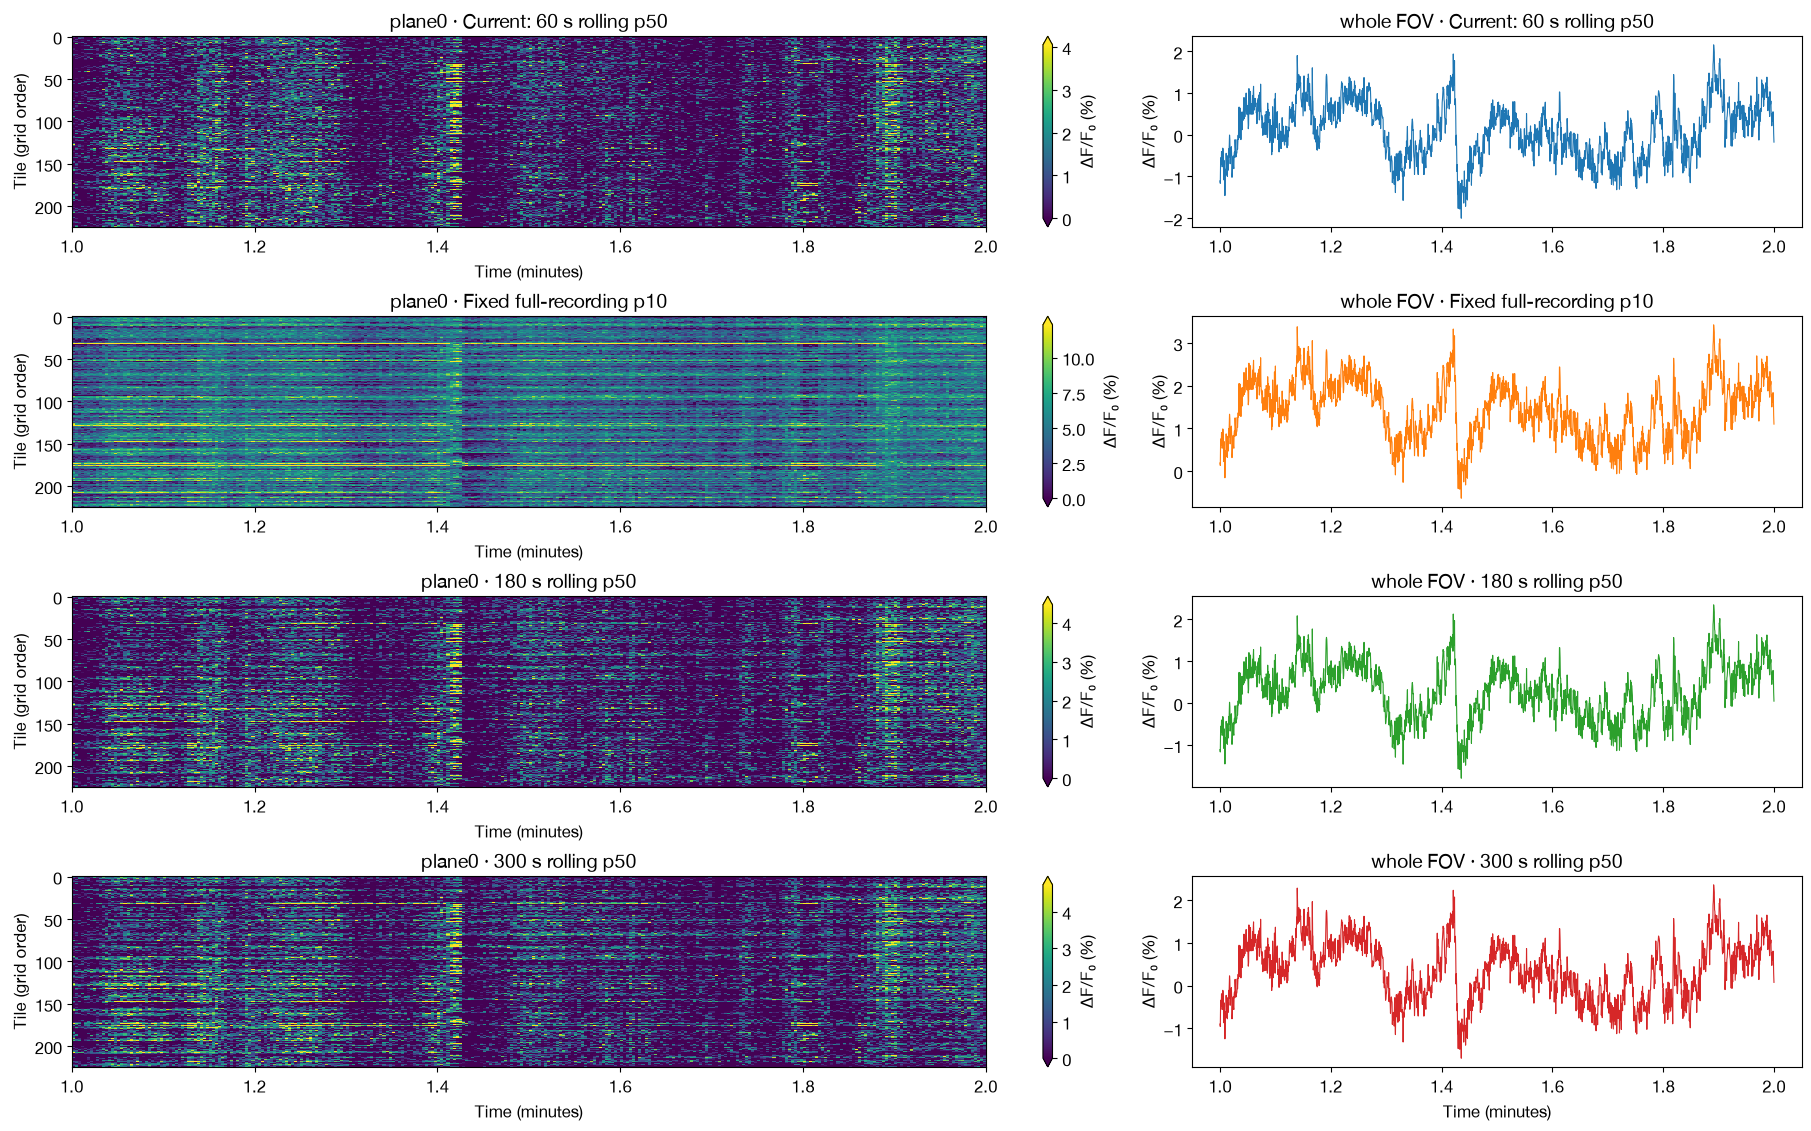

In [6]:
if ZOOM_MIN is not None:
    use = (s['time_s'] >= ZOOM_MIN[0] * 60) & (s['time_s'] <= ZOOM_MIN[1] * 60)
    if use.sum() < 2:
        raise ValueError(f'zoom window {ZOOM_MIN} min is outside the recording')
    fig, axes = plt.subplots(len(methods), 2, figsize=(18, 2.8 * len(methods)), constrained_layout=True,
                             squeeze=False, gridspec_kw={'width_ratios': [3, 2]})
    tile0 = s['tiles'][0]
    for row, (m, color) in enumerate(zip(methods, plotting._colors(len(methods)))):
        sub = tile0['dff'][m][:, use]
        ap.plot_tile_heatmap(sub, s['fs'], axes[row, 0], title=f"{tile0['plane'].name} · {m}", bin_s=0.2,
                             t0_s=s['time_s'][use][0])
        axes[row, 1].plot(s['time_s'][use] / 60, s['wf'][m][use] * 100, color=color, lw=0.8)
        axes[row, 1].set(title=f'whole FOV · {m}', ylabel='ΔF/F₀ (%)')
    axes[-1, 1].set_xlabel('Time (minutes)')

## What running removes

For each baseline, whole-FOV ΔF/F before and after the running regression, with running speed on top. Grey bands mark running periods. Also shown: variance explained (in-sample and held-out), the fitted kernels, and the current method's tile heatmap before and after. This section runs whether or not `regress_running` is set; it needs a speed column.

,r2_in_sample,r2_held_out,running_indicator_beta_pp,frames_used
method,,,,
Current: 60 s rolling p50,0.190,0.139,0.0,16718
Fixed full-recording p10,0.239,0.128,0.0,16718
180 s rolling p50,0.291,0.271,0.0,16718
300 s rolling p50,0.280,0.223,0.0,16718


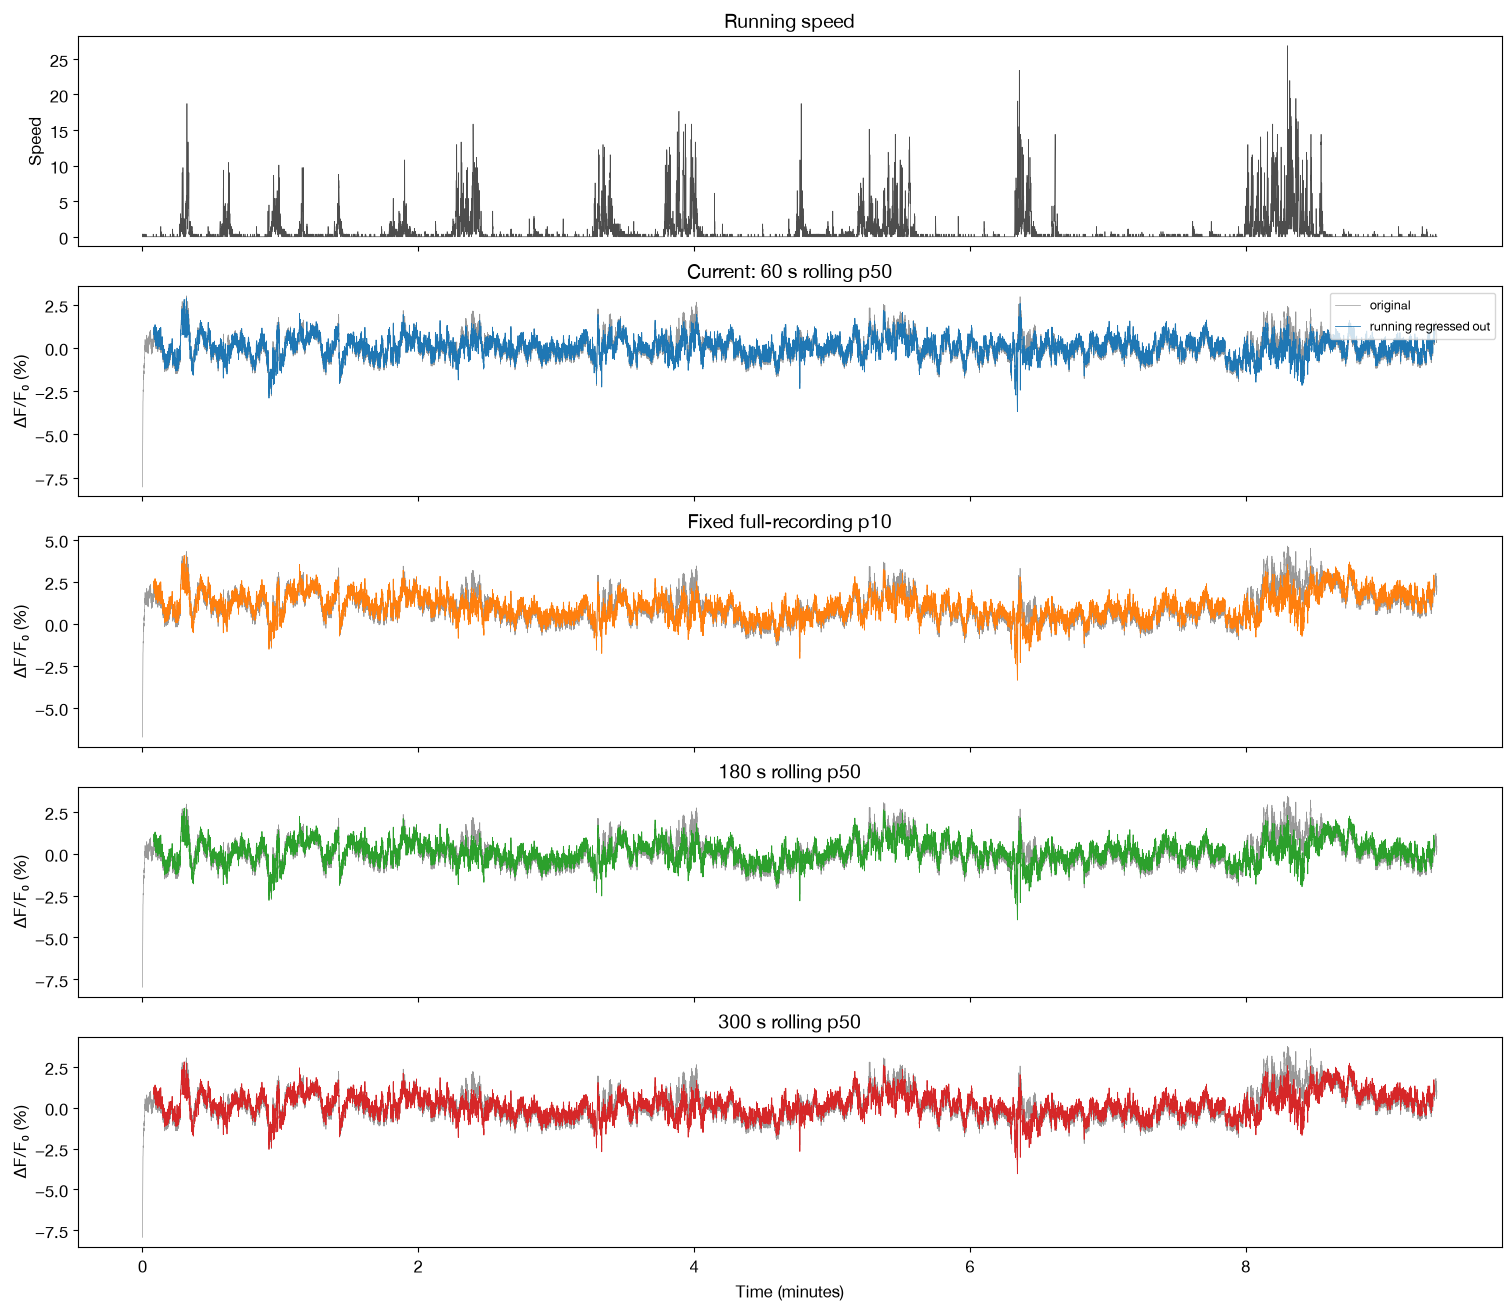

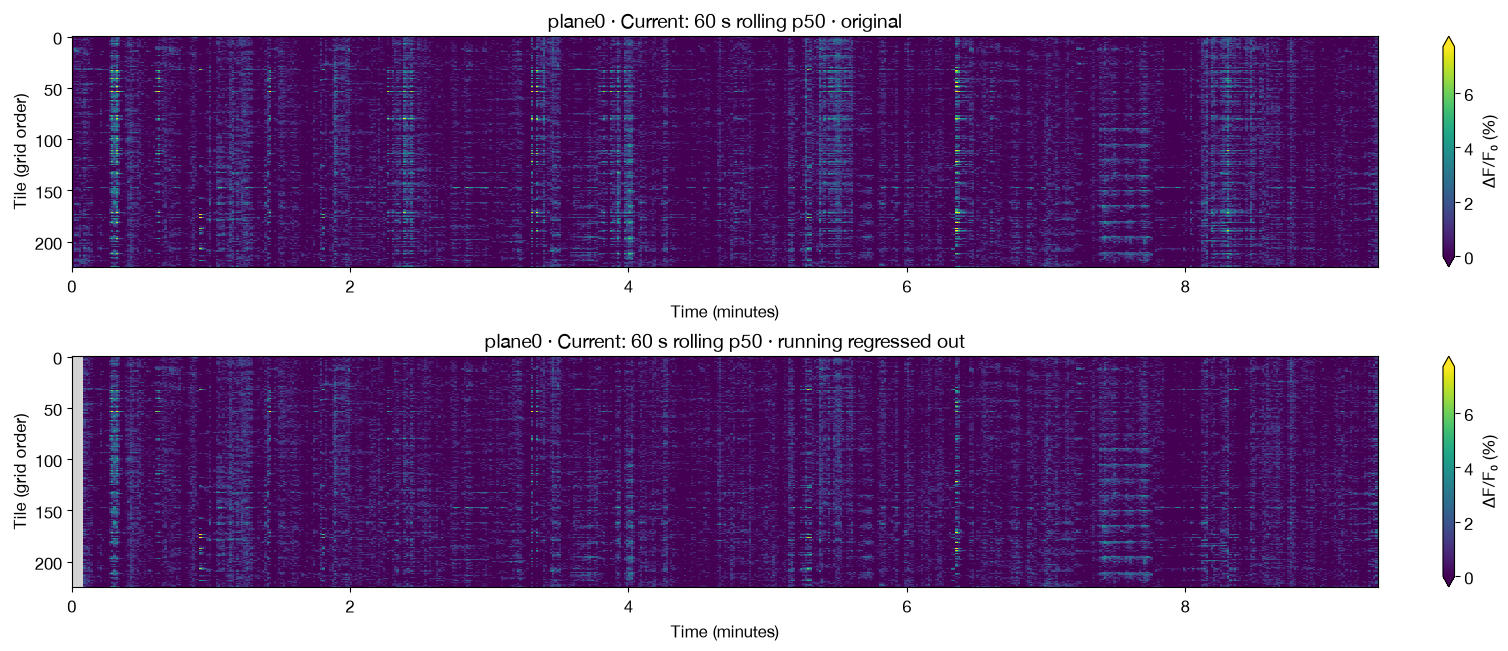

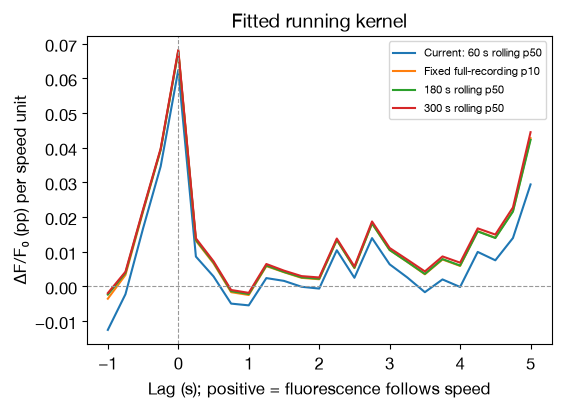

In [7]:
b = s['behavior']
if b is None or b.speed is None:
    print(f'{RECORDING}: no running speed in the behaviour table')
else:
    r = s if s['regress_running'] else session.apply_running_regression(s, RUNNING_MODEL)
    display(r['regression']['table'].round(3))
    ap.plot_running_kernels(r['regression']['lags_s'], r['regression']['kernels'])
    fig, axes = plt.subplots(len(methods) + 1, 1, figsize=(15, 2.6 * (len(methods) + 1)),
                             sharex=True, constrained_layout=True)
    minutes = s['time_s'] / 60
    axes[0].plot(minutes, b.speed, color='0.3', lw=0.5)
    axes[0].set(title='Running speed', ylabel='Speed')
    for ax, color, m in zip(axes[1:], plotting._colors(len(methods)), methods):
        ax.fill_between(minutes, 0, 1, where=r['running'], transform=ax.get_xaxis_transform(), color='0.85')
        ax.plot(minutes, r['wf_original'][m] * 100, color='0.6', lw=0.5, label='original')
        ax.plot(minutes, r['wf'][m] * 100, color=color, lw=0.6, label='running regressed out')
        ax.set(title=m, ylabel='ΔF/F₀ (%)')
    axes[1].legend(fontsize=9, loc='upper right')
    axes[-1].set_xlabel('Time (minutes)')
    display(fig); plt.close(fig)
    m0 = methods[0]
    for t in r['tiles']:
        fig, axes = plt.subplots(2, 1, figsize=(15, 6.4), constrained_layout=True)
        vmax = ap.robust_limit([t['dff_original'][m0] * 100], 99)
        ap.plot_tile_heatmap(t['dff_original'][m0], s['fs'], axes[0], title=f"{t['plane'].name} · {m0} · original", vmax=vmax, bin_s=BIN_S)
        ap.plot_tile_heatmap(t['dff'][m0], s['fs'], axes[1], title=f"{t['plane'].name} · {m0} · running regressed out", vmax=vmax, bin_s=BIN_S)
        display(fig); plt.close(fig)

## Save running-regressed ΔF/F

Writes whole-FOV and tile running-regressed ΔF/F for every baseline, plus the variance-explained table and settings, to `<derived_root>/running_regressed/` (a local folder set in the config, never the share). Set `SAVE_RUNNING_REGRESSED = True` to run it.

In [8]:
SAVE_RUNNING_REGRESSED = False
if SAVE_RUNNING_REGRESSED:
    sr = s if s['regress_running'] else session.apply_running_regression(s, RUNNING_MODEL)
    print('Saved to', session.save_running_regressed(sr))